In [32]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [33]:
df_meteo = pd.read_parquet("../data/processed/datos_meteo_Valencia_91-25(month).parquet")
df_meteo.head()

,temp_med_mar (Cº),temp_med_mes (Cº),temp_med_max (Cº),temp_med_min (Cº),temp_abs_max (Cº),temp_abs_min (Cº),dias_temp>30,total_precip_mes (mm),precip_max (mm),dias_precip>10mm,dias_precip>30mm,dias_lluvia,dias_granizo,dias_tormenta,humedad_med (%),presion_max (hPa),presion_min (hPa),presion_med (hPa),viento_vel_max (km/h),viento_vel_med (km/h)
1991-01,13.6,11.1,15.3,6.8,22.5,1.2,0,104.2,32.4,3,2,7,1,1,74.580645,1030.4,1013.4,1022.179301,45.4,20.441801
1991-02,12.5,10.9,15.1,6.6,21.5,0.4,0,67.7,29.5,2,0,7,0,1,74.302083,1028.3,997.6,1014.741815,49.9,19.540625
1991-03,13.4,14.5,18.9,10.1,26.6,6.0,0,82.7,46.0,2,1,15,0,0,76.641129,1025.8,984.3,1009.190591,40.3,16.776747
1991-04,14.5,14.7,19.5,9.8,24.5,5.6,0,37.5,14.9,2,0,10,0,1,70.225000,1023.7,999.2,1013.787639,52.7,16.190417
1991-05,16.5,16.2,21.3,11.0,27.5,6.0,0,21.3,5.4,0,0,8,0,1,66.404570,1030.7,1004.2,1015.025538,30.9,12.288844


In [34]:
matriz_corr_pearson = df_meteo.corr(method= "pearson")
matriz_corr_spearman = df_meteo.corr(method= "spearman")

In [35]:
print(matriz_corr_pearson)

                       temp_med_mar (Cº)  temp_med_mes (Cº)  \
temp_med_mar (Cº)               1.000000           0.943628   
temp_med_mes (Cº)               0.943628           1.000000   
temp_med_max (Cº)               0.935650           0.995246   
temp_med_min (Cº)               0.943118           0.996043   
temp_abs_max (Cº)               0.825373           0.908159   
temp_abs_min (Cº)               0.915484           0.974556   
dias_temp>30                    0.757135           0.773734   
total_precip_mes (mm)          -0.037216          -0.135550   
precip_max (mm)                 0.015692          -0.074987   
dias_precip>10mm               -0.059952          -0.147005   
dias_precip>30mm               -0.023133          -0.105371   
dias_lluvia                    -0.193652          -0.241131   
dias_granizo                    0.047027           0.041398   
dias_tormenta                   0.395416           0.389853   
humedad_med (%)                -0.020823          -0.16

In [36]:
print(matriz_corr_spearman)

                       temp_med_mar (Cº)  temp_med_mes (Cº)  \
temp_med_mar (Cº)               1.000000           0.917762   
temp_med_mes (Cº)               0.917762           1.000000   
temp_med_max (Cº)               0.911973           0.994388   
temp_med_min (Cº)               0.916168           0.994439   
temp_abs_max (Cº)               0.814516           0.920131   
temp_abs_min (Cº)               0.890982           0.971635   
dias_temp>30                    0.845949           0.892049   
total_precip_mes (mm)          -0.105890          -0.198020   
precip_max (mm)                -0.063514          -0.157607   
dias_precip>10mm               -0.069825          -0.157663   
dias_precip>30mm               -0.021602          -0.111280   
dias_lluvia                    -0.184417          -0.239483   
dias_granizo                    0.033214           0.022518   
dias_tormenta                   0.410005           0.412409   
humedad_med (%)                -0.045903          -0.19

In [37]:
matriz_otonio = df_meteo[df_meteo.index.month.isin([8, 9, 10, 11, 12])]
matriz_correlaciones_otonio = matriz_otonio.corr(method= "spearman")
matriz_correlaciones_otonio


,temp_med_mar (Cº),temp_med_mes (Cº),temp_med_max (Cº),temp_med_min (Cº),temp_abs_max (Cº),temp_abs_min (Cº),dias_temp>30,total_precip_mes (mm),precip_max (mm),dias_precip>10mm,dias_precip>30mm,dias_lluvia,dias_granizo,dias_tormenta,humedad_med (%),presion_max (hPa),presion_min (hPa),presion_med (hPa),viento_vel_max (km/h),viento_vel_med (km/h)
temp_med_mar (Cº),1.000000,0.976213,0.970893,0.973431,0.903111,0.946404,0.905251,-0.083174,-0.054025,-0.064432,-0.083888,-0.191543,0.112928,0.394343,-0.179734,-0.812108,0.354134,-0.409721,-0.570540,-0.729110
temp_med_mes (Cº),0.976213,1.000000,0.994773,0.994808,0.927964,0.974790,0.922281,-0.148946,-0.123437,-0.121302,-0.138246,-0.235960,0.107957,0.393606,-0.212793,-0.822662,0.328990,-0.437344,-0.548224,-0.708897
temp_med_max (Cº),0.970893,0.994773,1.000000,0.981335,0.934152,0.962290,0.931472,-0.187398,-0.157483,-0.160195,-0.167377,-0.269060,0.109014,0.394082,-0.254312,-0.815046,0.326059,-0.428819,-0.550062,-0.710942
temp_med_min (Cº),0.973431,0.994808,0.981335,1.000000,0.915556,0.978097,0.908195,-0.104373,-0.083543,-0.077585,-0.107596,-0.192445,0.107208,0.398788,-0.173097,-0.827740,0.326029,-0.447551,-0.546498,-0.704501
temp_abs_max (Cº),0.903111,0.927964,0.934152,0.915556,1.000000,0.884787,0.921073,-0.140840,-0.121242,-0.087922,-0.170593,-0.194787,0.127975,0.371566,-0.319554,-0.795855,0.259559,-0.477606,-0.483336,-0.607749
temp_abs_min (Cº),0.946404,0.974790,0.962290,0.978097,0.884787,1.000000,0.887173,-0.119609,-0.102984,-0.104969,-0.113059,-0.196217,0.080641,0.384895,-0.134922,-0.785751,0.341071,-0.388961,-0.560851,-0.717110
dias_temp>30,0.905251,0.922281,0.931472,0.908195,0.921073,0.887173,1.000000,-0.185824,-0.167854,-0.144604,-0.191617,-0.249784,0.134915,0.366128,-0.279517,-0.785345,0.285978,-0.432373,-0.494210,-0.638904
total_precip_mes (mm),-0.083174,-0.148946,-0.187398,-0.104373,-0.140840,-0.119609,-0.185824,1.000000,0.954739,0.926427,0.710332,0.691803,0.179263,0.370326,0.474907,0.098158,-0.037536,0.014190,0.127356,0.093491
precip_max (mm),-0.054025,-0.123437,-0.157483,-0.083543,-0.121242,-0.102984,-0.167854,0.954739,1.000000,0.879839,0.744929,0.562929,0.178518,0.379987,0.420039,0.104606,0.026658,0.080961,0.077706,0.047536
dias_precip>10mm,-0.064432,-0.121302,-0.160195,-0.077585,-0.087922,-0.104969,-0.144604,0.926427,0.879839,1.000000,0.631981,0.598991,0.164378,0.329697,0.401358,0.072361,-0.015843,0.016312,0.151177,0.117278


In [38]:
from scipy.stats import spearmanr

def crear_tabla_spearmanr(df_analisis:pd.DataFrame):
    lista_columnas = df_meteo.columns
    resultados = []

    for col1 in range(len(lista_columnas)):
        for col2 in range(col1, len(lista_columnas)):
            var1 = lista_columnas[col1]
            var2 = lista_columnas[col2]

            if ('temp' in var1 and 'temp' in var2) or (var1 == var2):
                continue

            coef_corr, p_valor = spearmanr(df_analisis[var1], df_analisis[var2], nan_policy='omit')

            es_significativo = p_valor < 0.05
            
            if p_valor < 0.05 and abs(coef_corr) >= 0.30:
                resultados.append({
                    'Variable 1': var1,
                    'Variable 2': var2,
                    'Spearman (r)': round(coef_corr, 3),
                    'P-valor': f"{p_valor:.5f}"
                })


    tabla_correlaciones = pd.DataFrame(resultados)

    tabla_correlaciones['fuerza_abs'] = tabla_correlaciones['Spearman (r)'].abs()
    tabla_correlaciones = tabla_correlaciones.sort_values(by='fuerza_abs', ascending=False).drop(columns=['fuerza_abs'])

    return tabla_correlaciones
    # with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    #     display(tabla_correlaciones)

def convertir_tabla_en_imagen(df_interes:pd.DataFrame):
    # 1. Asegúrate de tener tu dataframe listo (ej. tabla_interes)
    df_para_guardar = tabla_interes.copy()

    # 2. Creamos la figura
    fig, ax = plt.subplots(figsize=(10, len(df_para_guardar) * 0.4 + 1)) # Ajusta la altura según el número de filas
    ax.axis('tight')
    ax.axis('off')

    # 3. Dibujamos la tabla
    tabla_img = ax.table(
        cellText=df_para_guardar.values,
        colLabels=df_para_guardar.columns,
        cellLoc='center',
        loc='center'
    )

    # 4. Estilizamos un poco la tabla (tamaño de fuente y ancho)
    tabla_img.auto_set_font_size(False)
    tabla_img.set_fontsize(10)
    tabla_img.scale(1.2, 1.5)

    # 5. Guardamos la imagen en tu proyecto
    plt.savefig('tabla_correlaciones_criticas.png', bbox_inches='tight', dpi=300)
    plt.show()

    print("¡Tabla guardada correctamente como 'tabla_correlaciones_criticas.png'!")

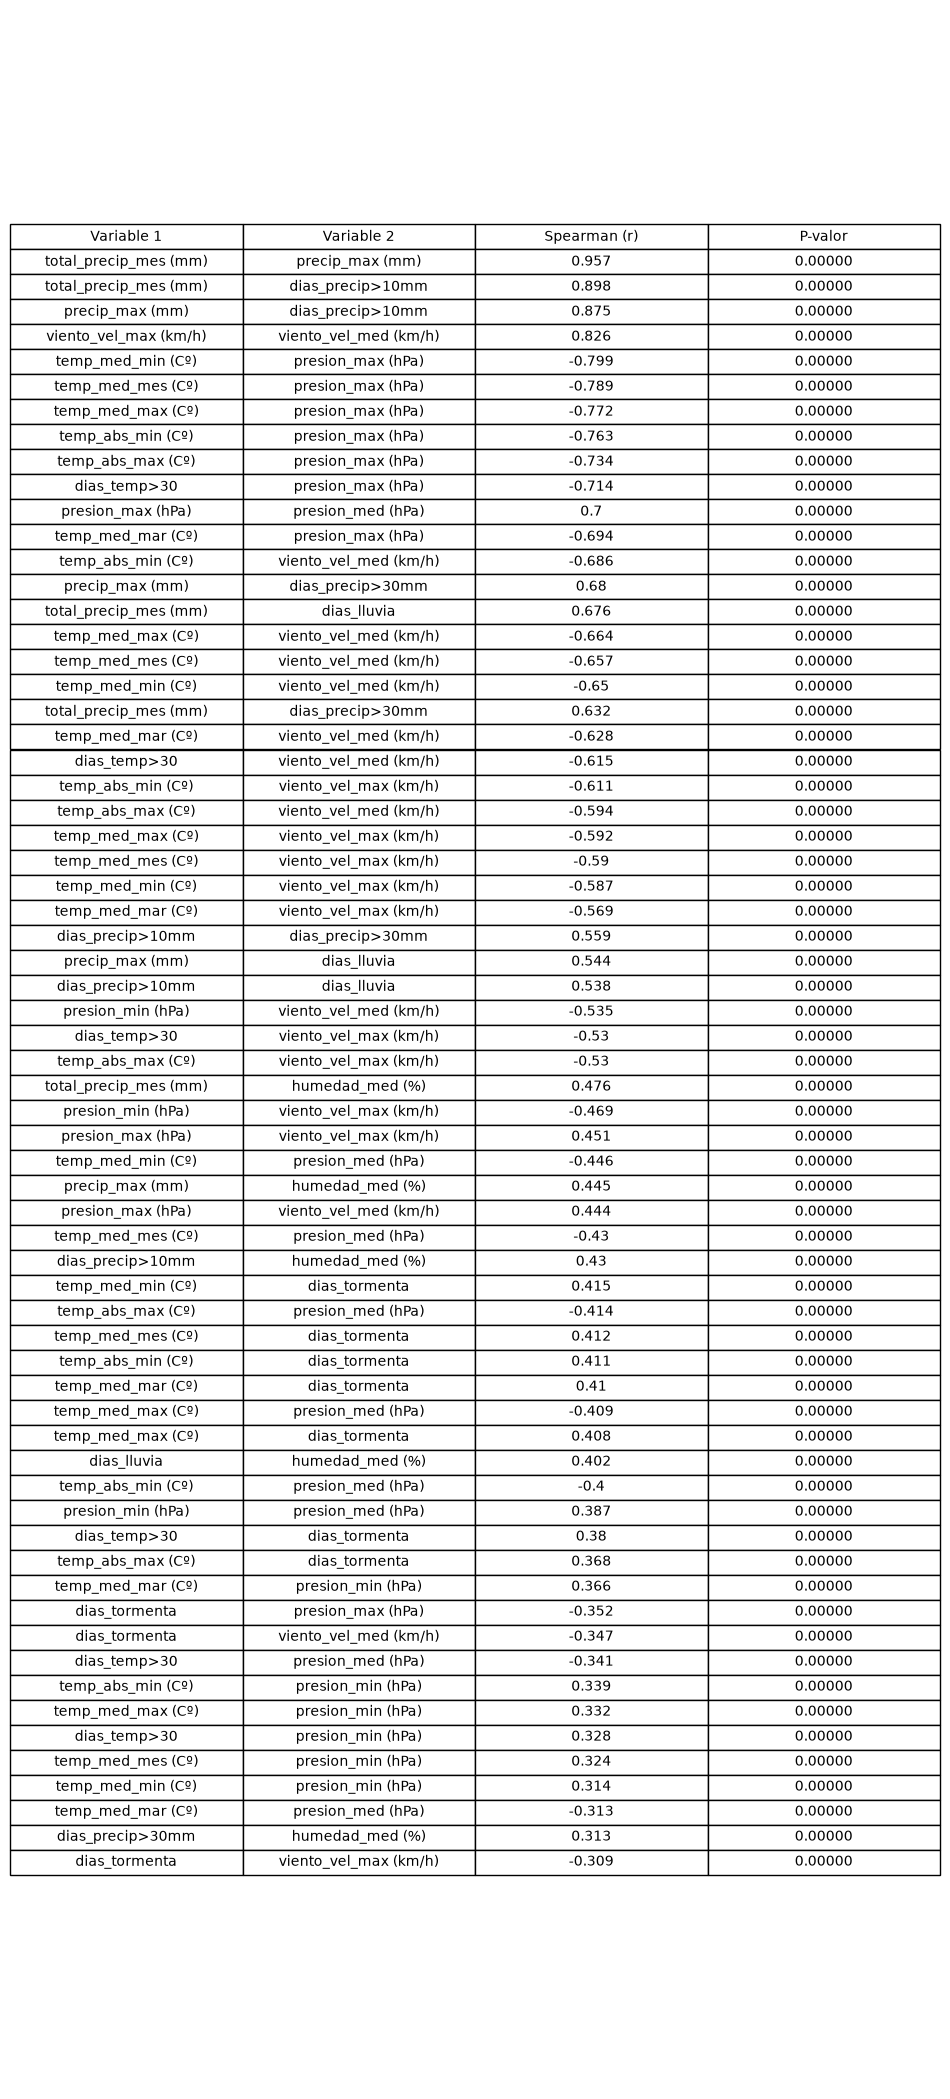

¡Tabla guardada correctamente como 'tabla_correlaciones_criticas.png'!


In [43]:
tabla_interes = crear_tabla_spearmanr(df_meteo)

convertir_tabla_en_imagen(tabla_interes)

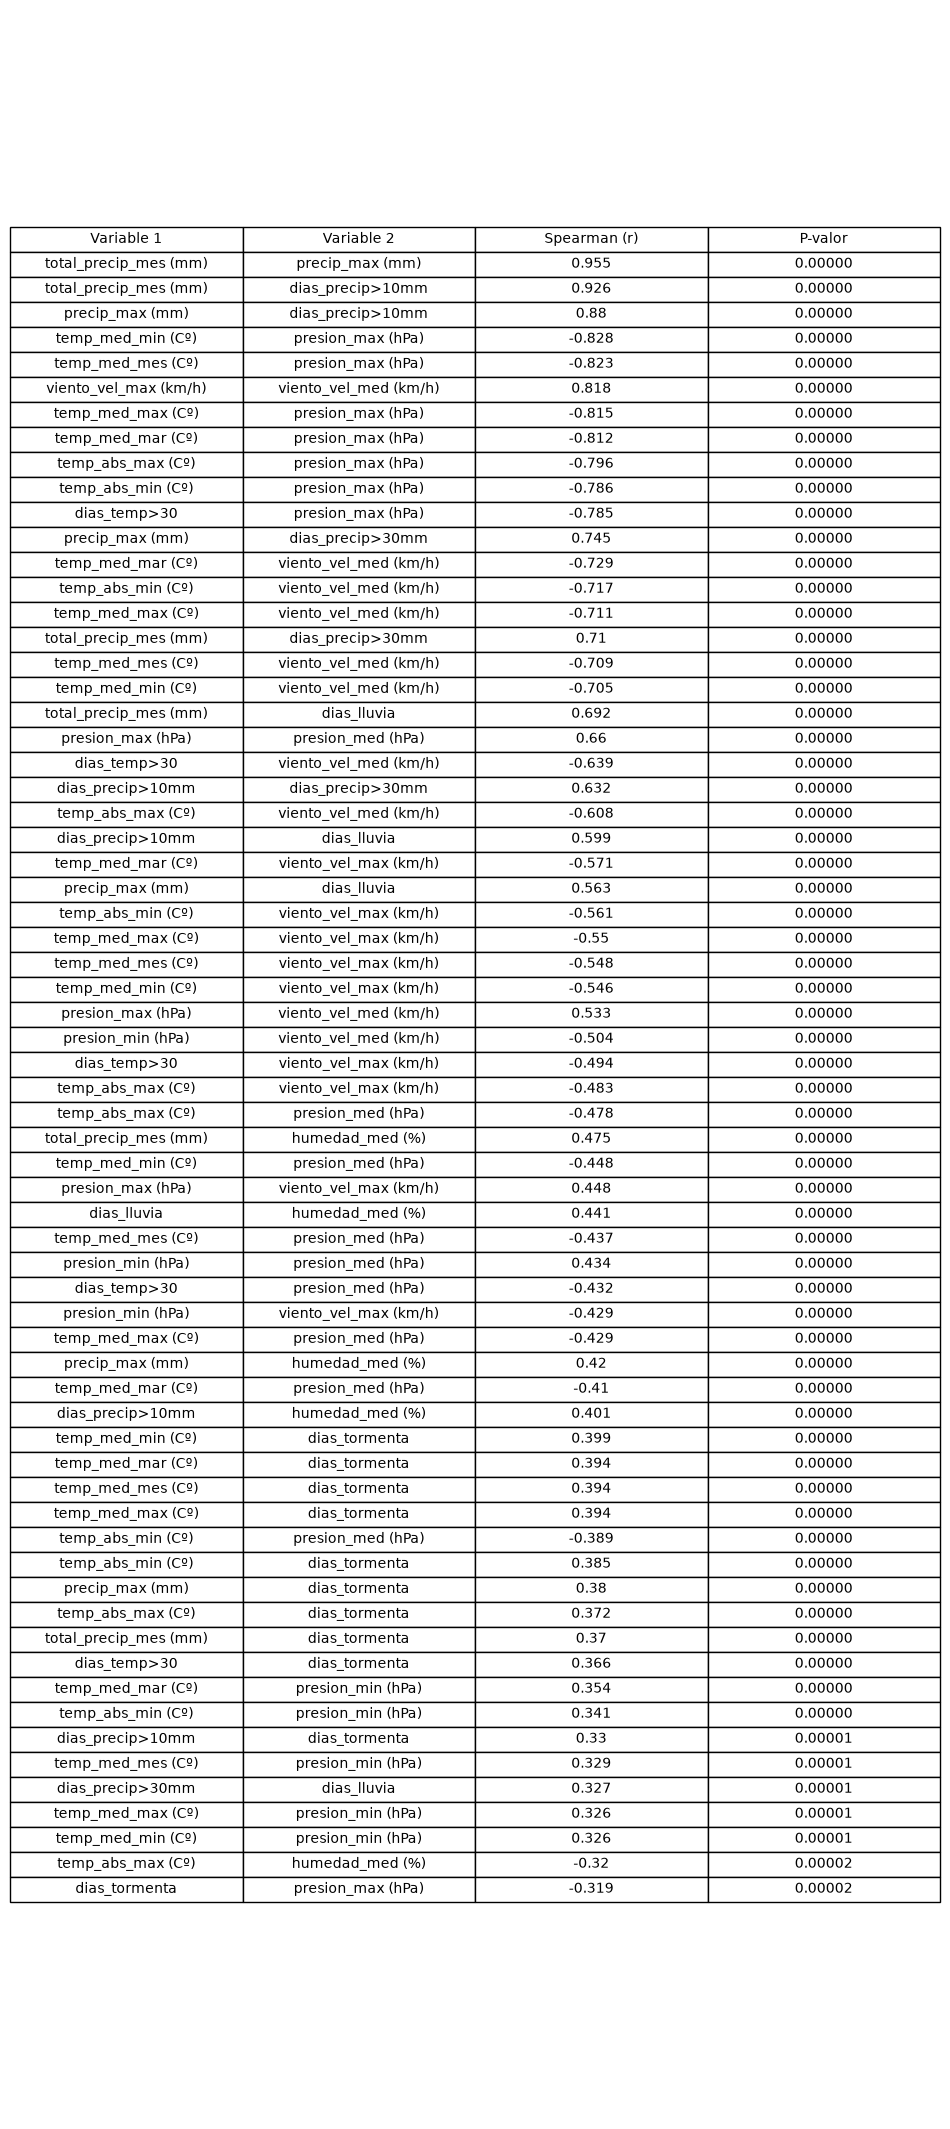

¡Tabla guardada correctamente como 'tabla_correlaciones_criticas.png'!


In [44]:
tabla_interes = crear_tabla_spearmanr(matriz_otonio)
# with pd.option_context('display.max_rows', None, 'display.max_columns', None):
#         display(tabla_interes)
convertir_tabla_en_imagen(tabla_interes)